# Exploratory Data Analysis

This section explores sales, profitability, customer, product, geographic,
and delivery performance to identify key business patterns and supply chain
opportunities.

## 1. Load Analytical Dataset

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"D:\DataCo_Smart_Supply_Chain_Analytics\data\processed\DataCo_analytics.csv"
df = pd.read_csv(
    file_path,
    parse_dates=["order date (DateOrders)","shipping date (DateOrders)"]
)



In [51]:
df[date_columns].dtypes

order date (DateOrders)       datetime64[ns]
shipping date (DateOrders)    datetime64[ns]
dtype: object

## 2. Sales & Profitability Overview

This section evaluates overall sales and profitability performance and
examines how revenue and profit change over time.

In [52]:
sales_profit = {
    "Total Sales": df["Sales"].sum(),
    "Total Profit": df["Benefit per order"].sum(),
    "Profit Margin": df["Benefit per order"].sum() / df["Sales"].sum(),
    "Total Orders": df["Order Id"].nunique(),
    "Total Quantity": df["Order Item Quantity"].sum()
}

pd.Series(sales_profit)

Total Sales       3.678474e+07
Total Profit      3.966903e+06
Profit Margin     1.078410e-01
Total Orders      6.575200e+04
Total Quantity    3.840790e+05
dtype: float64

## 3. Sales Trend Over Time

Monthly sales and profit are analyzed to identify growth patterns,
seasonality, and changes in business performance.

In [54]:
monthly_performance = (
    df.groupby("Order Year Month")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum"),
          Orders=("Order Id", "nunique")
      )
      .reset_index()
)

monthly_performance.head()

,Order Year Month,Sales,Profit,Orders
0,2015-01,1.051590e+06,111660.740132,1787
1,2015-02,9.270099e+05,99140.660196,1585
2,2015-03,1.051254e+06,113778.210191,1781
3,2015-04,1.014463e+06,108083.679957,1710
4,2015-05,1.050478e+06,112147.900143,1776


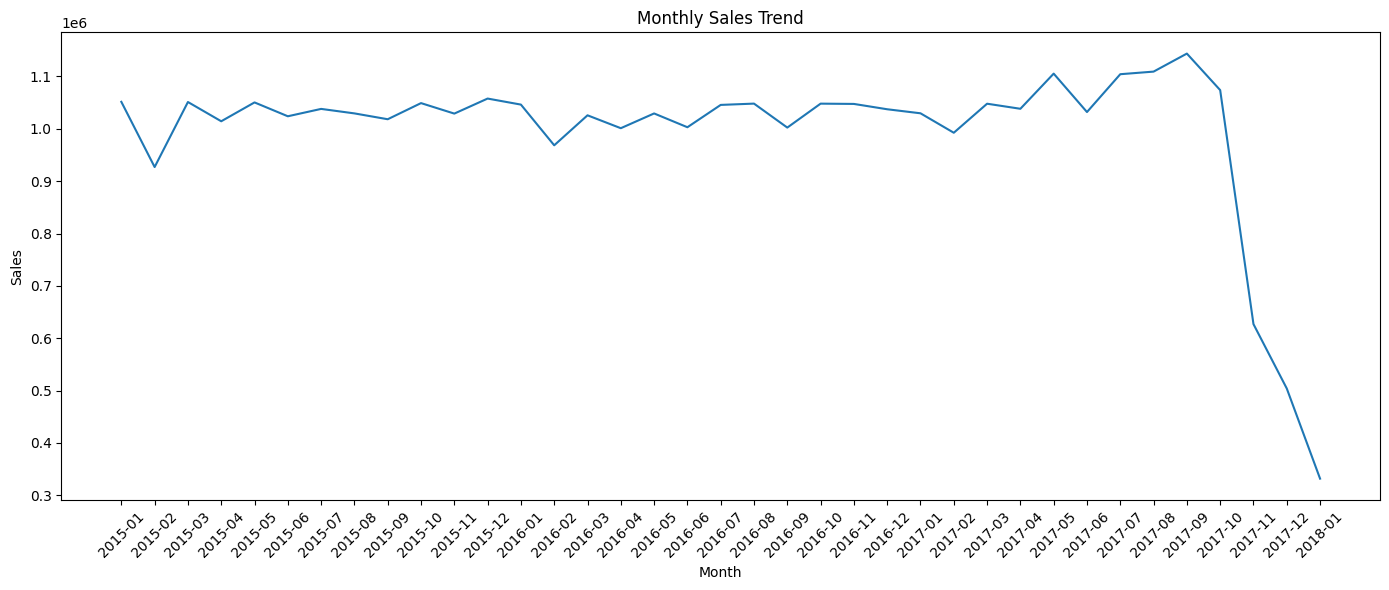

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["Order Year Month"],
    monthly_performance["Sales"]
)

plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 4. Category Performance

Product categories are compared based on sales, profit, quantity, and
profitability to identify high-performing and underperforming categories.

In [56]:
category_performance = (
    df.groupby("Category Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum"),
          Quantity=("Order Item Quantity", "sum"),
          Orders=("Order Id", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

category_performance

,Sales,Profit,Quantity,Orders
Category Name,,,,
Fishing,6.929654e+06,756220.767190,17325,15164
Cleats,4.431943e+06,494636.919791,73734,20386
Camping & Hiking,4.118426e+06,427455.568106,13729,12299
Cardio Equipment,3.694843e+06,383011.098485,37587,11355
Women's Apparel,3.147800e+06,350421.029567,62956,17869
Water Sports,3.113845e+06,325146.960038,15540,13758
Men's Footwear,2.891758e+06,311902.820214,22246,18783
Indoor/Outdoor Games,2.888994e+06,318451.430554,57803,16623
Shop By Sport,1.309522e+06,129813.960315,32726,10136


In [57]:
category_performance["Profit Margin"] = (
    category_performance["Profit"]
    / category_performance["Sales"]
)

category_performance

,Sales,Profit,Quantity,Orders,Profit Margin
Category Name,,,,,
Fishing,6.929654e+06,756220.767190,17325,15164,0.109128
Cleats,4.431943e+06,494636.919791,73734,20386,0.111607
Camping & Hiking,4.118426e+06,427455.568106,13729,12299,0.103791
Cardio Equipment,3.694843e+06,383011.098485,37587,11355,0.103661
Women's Apparel,3.147800e+06,350421.029567,62956,17869,0.111323
Water Sports,3.113845e+06,325146.960038,15540,13758,0.104420
Men's Footwear,2.891758e+06,311902.820214,22246,18783,0.107859
Indoor/Outdoor Games,2.888994e+06,318451.430554,57803,16623,0.110229
Shop By Sport,1.309522e+06,129813.960315,32726,10136,0.099131


## 5. Market Performance

Market-level performance is analyzed to identify differences in sales,
profitability, and order volume across geographic markets.

In [58]:
market_performance = (
    df.groupby("Market")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum"),
          Orders=("Order Id", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

market_performance["Profit Margin"] = (
    market_performance["Profit"]
    / market_performance["Sales"]
)

market_performance

,Sales,Profit,Orders,Profit Margin
Market,,,,
Europe,1.087240e+07,1.169443e+06,18561,0.107561
LATAM,1.027761e+07,1.123322e+06,17181,0.109298
Pacific Asia,8.273744e+06,8.577534e+05,17577,0.103672
USCA,5.066529e+06,5.643138e+05,8579,0.111381
Africa,2.294453e+06,2.520712e+05,3854,0.109861


## 6. Delivery Performance

Delivery performance is analyzed to identify the scale of late deliveries
and compare operational performance across shipping modes.

In [59]:
delivery_summary = {
    "Late Delivery Rate": df["Late Delivery Flag"].mean(),
    "On Time Delivery Rate": df["On Time Delivery"].mean(),
    "Average Shipping Days": df["Days for shipping (real)"].mean(),
    "Average Scheduled Days": df["Days for shipment (scheduled)"].mean()
}

pd.Series(delivery_summary)

Late Delivery Rate        0.572793
On Time Delivery Rate     0.427207
Average Shipping Days     3.497654
Average Scheduled Days    2.931847
dtype: float64

In [60]:
shipping_performance = (
    df.groupby("Shipping Mode")
      .agg(
          Orders=("Order Id", "nunique"),
          Avg_Shipping_Days=("Days for shipping (real)", "mean"),
          Late_Delivery_Rate=("Late Delivery Flag", "mean"),
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum")
      )
      .sort_values("Late_Delivery_Rate", ascending=False)
)

shipping_performance

,Orders,Avg_Shipping_Days,Late_Delivery_Rate,Sales,Profit
Shipping Mode,,,,,
First Class,10079,2.000000,1.000000,5.674370e+06,6.431219e+05
Second Class,12778,3.990828,0.797308,7.145445e+06,7.503082e+05
Same Day,3571,0.478279,0.478279,1.942529e+06,2.030184e+05
Standard Class,39324,3.995907,0.397682,2.202239e+07,2.370454e+06


## 7. Product Performance

Product-level performance is analyzed to identify the products that
generate the highest sales and profit and to evaluate revenue concentration.

In [61]:
product_performance = (
    df.groupby(["Product Card Id", "Product Name"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum"),
          Quantity=("Order Item Quantity", "sum"),
          Orders=("Order Id", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

product_performance["Profit Margin"] = (
    product_performance["Profit"] /
    product_performance["Sales"]
)

product_performance.head(15)

,,Sales,Profit,Quantity,Orders,Profit Margin
Product Card Id,Product Name,,,,,
1004,Field & Stream Sportsman 16 Gun Fire Safe,6.929654e+06,756220.767190,17325,15164,0.109128
365,Perfect Fitness Perfect Rip Deck,4.421143e+06,493828.299782,73698,20359,0.111697
957,Diamondback Women's Serene Classic Comfort Bi,4.118426e+06,427455.568106,13729,12299,0.103791
191,Nike Men's Free 5.0+ Running Shoe,3.667633e+06,379915.818503,36680,11092,0.103586
502,Nike Men's Dri-FIT Victory Golf Polo,3.147800e+06,350421.029567,62956,17869,0.111323
1073,Pelican Sunstream 100 Kayak,3.099845e+06,324076.370020,15500,13727,0.104546
403,Nike Men's CJ Elite 2 TD Football Cleat,2.891758e+06,311902.820214,22246,18783,0.107859
1014,O'Brien Men's Neoprene Life Vest,2.888994e+06,318451.430554,57803,16623,0.110229
627,Under Armour Girls' Toddler Spine Surge Runni,1.269083e+06,126278.510299,31735,9825,0.099504


## 8. Customer Performance

Customer-level performance is analyzed using distinct orders and total
sales to identify high-value customers and customer concentration.

In [63]:
customer_performance = (
    df.groupby("Customer Id")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum"),
          Orders=("Order Id", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

customer_performance["Profit Margin"] = (
    customer_performance["Profit"] /
    customer_performance["Sales"]
)

customer_performance.head(10)

,Sales,Profit,Orders,Profit Margin
Customer Id,,,,
791,10524.170178,-866.380008,13,-0.082323
9371,9299.030207,1346.579992,11,0.144809
8766,9296.140186,1495.159984,11,0.160837
1657,9223.710152,2196.919992,11,0.238182
2641,9130.920224,2441.970003,11,0.267440
1288,9019.110199,403.109983,12,0.044695
3710,9019.100208,1055.130010,14,0.116988
4249,8918.850134,439.709982,13,0.049301
5654,8904.950211,1045.359995,15,0.117391


## 10. Sales vs Profitability

Sales and profitability are compared to identify categories with high
revenue but relatively weak margins and categories with lower revenue
but stronger profitability.

In [64]:
category_matrix = (
    df.groupby("Category Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum")
      )
)

category_matrix["Profit Margin"] = (
    category_matrix["Profit"] /
    category_matrix["Sales"]
)

category_matrix

,Sales,Profit,Profit Margin
Category Name,,,
Accessories,1.336715e+05,16643.520074,0.124511
As Seen on TV!,2.059794e+04,714.429980,0.034685
Baby,1.222956e+04,1525.029992,0.124700
Baseball & Softball,9.405715e+04,12762.130067,0.135685
Basketball,2.709933e+04,1845.670003,0.068108
Books,1.258740e+04,883.010008,0.070150
Boxing & MMA,8.520541e+04,8641.370006,0.101418
CDs,3.059590e+03,383.850000,0.125458
Cameras,2.676077e+05,30289.799946,0.113187


## 11. Revenue Concentration — Pareto Analysis

A Pareto analysis is used to determine how concentrated total sales are
among products.

In [65]:
pareto = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

pareto["Cumulative Sales"] = pareto["Sales"].cumsum()

pareto["Cumulative Sales %"] = (
    pareto["Cumulative Sales"] /
    pareto["Sales"].sum()
)

pareto.head(20)

,Product Name,Sales,Cumulative Sales,Cumulative Sales %
0,Field & Stream Sportsman 16 Gun Fire Safe,6.929654e+06,6.929654e+06,0.188384
1,Perfect Fitness Perfect Rip Deck,4.421143e+06,1.135080e+07,0.308574
2,Diamondback Women's Serene Classic Comfort Bi,4.118426e+06,1.546922e+07,0.420534
3,Nike Men's Free 5.0+ Running Shoe,3.667633e+06,1.913686e+07,0.520239
4,Nike Men's Dri-FIT Victory Golf Polo,3.147800e+06,2.228466e+07,0.605813
5,Pelican Sunstream 100 Kayak,3.099845e+06,2.538450e+07,0.690082
6,Nike Men's CJ Elite 2 TD Football Cleat,2.891758e+06,2.827626e+07,0.768695
7,O'Brien Men's Neoprene Life Vest,2.888994e+06,3.116525e+07,0.847233
8,Under Armour Girls' Toddler Spine Surge Runni,1.269083e+06,3.243433e+07,0.881734
9,Dell Laptop,6.630000e+05,3.309733e+07,0.899757


In [66]:
products_for_80 = (
    pareto["Cumulative Sales %"] <= 0.80
).sum()

products_for_80

np.int64(7)

## 12. Delivery Risk by Region

Delivery performance is compared across regions to identify geographic
areas with higher operational risk.

In [67]:
delivery_by_region = (
    df.groupby("Order Region")
      .agg(
          Orders=("Order Id", "nunique"),
          Late_Delivery_Rate=("Late Delivery Flag", "mean"),
          Avg_Shipping_Days=("Days for shipping (real)", "mean"),
          Avg_Scheduled_Days=("Days for shipment (scheduled)", "mean")
      )
      .sort_values("Late_Delivery_Rate", ascending=False)
)

delivery_by_region

,Orders,Late_Delivery_Rate,Avg_Shipping_Days,Avg_Scheduled_Days
Order Region,,,,
Central Africa,556,0.607036,3.560525,2.920692
Western Europe,10010,0.585156,3.498432,2.901029
South Asia,3335,0.585047,3.502005,2.904540
South of USA,1345,0.580964,3.492707,2.912732
Southeast Asia,4356,0.579830,3.496698,2.938463
East of USA,2323,0.579754,3.500940,2.916124
West Asia,2022,0.574971,3.486770,2.917291
East Africa,613,0.574514,3.514579,2.943844
Eastern Europe,1292,0.574490,3.500765,2.920918


## 13. Revenue Concentration

The Pareto analysis evaluates how concentrated revenue is across products.

The analysis shows that a small number of products contribute a large share
of total sales, indicating significant revenue concentration.

In [68]:
pareto["Cumulative Sales %"] = (
    pareto["Cumulative Sales"] / pareto["Sales"].sum()
)

products_to_reach_80 = (
    pareto["Cumulative Sales %"].ge(0.80).idxmax() + 1
)

sales_share_of_top_products = (
    pareto.loc[products_to_reach_80 - 1, "Cumulative Sales %"]
)

print("Products needed to reach 80% of sales:", products_to_reach_80)
print("Sales share:", sales_share_of_top_products)

Products needed to reach 80% of sales: 8
Sales share: 0.8472332953203134


## 14. Delivery Performance Validation

Delivery performance metrics are validated by comparing the calculated
shipping delay with the original delivery-related fields in the dataset.

This prevents incorrect business conclusions caused by differences between
the source fields and derived metrics.

In [69]:
delivery_validation = df[
    [
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Shipping Delay",
        "Delivery Status",
        "Late_delivery_risk",
        "Late Delivery Flag",
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ]
].copy()

delivery_validation.head()

,Days for shipping (real),Days for shipment (scheduled),Shipping Delay,Delivery Status,Late_delivery_risk,Late Delivery Flag,order date (DateOrders),shipping date (DateOrders)
0,3,4,-1,Advance shipping,0,0,2018-01-31 22:56:00,2018-02-03 22:56:00
1,5,4,1,Late delivery,1,1,2018-01-13 12:27:00,2018-01-18 12:27:00
2,4,4,0,Shipping on time,0,0,2018-01-13 12:06:00,2018-01-17 12:06:00
3,3,4,-1,Advance shipping,0,0,2018-01-13 11:45:00,2018-01-16 11:45:00
4,2,4,-2,Advance shipping,0,0,2018-01-13 11:24:00,2018-01-15 11:24:00


In [70]:
pd.crosstab(
    df["Late_delivery_risk"],
    df["Late Delivery Flag"],
    normalize="index"
)

Late Delivery Flag,0,1
Late_delivery_risk,,
0,0.945758,0.054242
1,0.000000,1.000000


In [71]:
pd.crosstab(
    df["Delivery Status"],
    df["Late Delivery Flag"],
    normalize="index"
)

Late Delivery Flag,0,1
Delivery Status,,
Advance shipping,1.000000,0.000000
Late delivery,0.000000,1.000000
Shipping canceled,0.429585,0.570415
Shipping on time,1.000000,0.000000


In [72]:
pd.crosstab(
    df["Shipping Mode"],
    df["Late_delivery_risk"],
    normalize="index"
)

Late_delivery_risk,0,1
Shipping Mode,,
First Class,0.046775,0.953225
Same Day,0.542570,0.457430
Second Class,0.233672,0.766328
Standard Class,0.619283,0.380717


## 15. Sales vs Profitability Matrix

Categories are classified based on sales contribution and profit margin
to identify high-value categories and categories that may require
profitability improvement.

In [73]:
category_matrix = (
    df.groupby("Category Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum")
      )
)

category_matrix["Profit Margin"] = (
    category_matrix["Profit"] /
    category_matrix["Sales"]
)

sales_median = category_matrix["Sales"].median()
margin_median = category_matrix["Profit Margin"].median()

category_matrix["Performance Segment"] = np.select(
    [
        (category_matrix["Sales"] >= sales_median) &
        (category_matrix["Profit Margin"] >= margin_median),

        (category_matrix["Sales"] >= sales_median) &
        (category_matrix["Profit Margin"] < margin_median),

        (category_matrix["Sales"] < sales_median) &
        (category_matrix["Profit Margin"] >= margin_median)
    ],
    [
        "High Sales / High Margin",
        "High Sales / Low Margin",
        "Low Sales / High Margin"
    ],
    default="Low Sales / Low Margin"
)

category_matrix.sort_values("Sales", ascending=False)

,Sales,Profit,Profit Margin,Performance Segment
Category Name,,,,
Fishing,6.929654e+06,756220.767190,0.109128,High Sales / Low Margin
Cleats,4.431943e+06,494636.919791,0.111607,High Sales / High Margin
Camping & Hiking,4.118426e+06,427455.568106,0.103791,High Sales / Low Margin
Cardio Equipment,3.694843e+06,383011.098485,0.103661,High Sales / Low Margin
Women's Apparel,3.147800e+06,350421.029567,0.111323,High Sales / High Margin
Water Sports,3.113845e+06,325146.960038,0.104420,High Sales / Low Margin
Men's Footwear,2.891758e+06,311902.820214,0.107859,High Sales / Low Margin
Indoor/Outdoor Games,2.888994e+06,318451.430554,0.110229,High Sales / Low Margin
Shop By Sport,1.309522e+06,129813.960315,0.099131,High Sales / Low Margin


## 16. Delivery Performance by Market

Delivery performance is compared across markets to identify geographic
differences in late-delivery risk and shipping efficiency.

In [74]:
delivery_by_market = (
    df.groupby("Market")
      .agg(
          Orders=("Order Id", "nunique"),
          Late_Delivery_Rate=("Late_delivery_risk", "mean"),
          Avg_Shipping_Days=("Days for shipping (real)", "mean"),
          Avg_Scheduled_Days=("Days for shipment (scheduled)", "mean")
      )
      .sort_values("Late_Delivery_Rate", ascending=False)
)

delivery_by_market

,Orders,Late_Delivery_Rate,Avg_Shipping_Days,Avg_Scheduled_Days
Market,,,,
Europe,18561,0.552078,3.487622,2.916779
Pacific Asia,17577,0.550460,3.500509,2.931144
USCA,8579,0.548006,3.484709,2.915849
Africa,3854,0.545893,3.511193,2.951180
LATAM,17181,0.543552,3.508567,2.950731


## 17. Order Status Analysis

Order status is analyzed to understand the distribution of completed,
pending, canceled, and other order outcomes and their impact on sales
performance.

In [75]:
order_status = (
    df.groupby("Order Status")
      .agg(
          Orders=("Order Id", "nunique"),
          Sales=("Sales", "sum"),
          Profit=("Benefit per order", "sum")
      )
      .sort_values("Orders", ascending=False)
)

order_status

,Orders,Sales,Profit
Order Status,,,
COMPLETE,21716,1.209531e+07,1.321736e+06
PENDING_PAYMENT,14382,8.106698e+06,8.438102e+05
PROCESSING,7901,4.504064e+06,4.948259e+05
PENDING,7321,4.120533e+06,4.357259e+05
CLOSED,7249,4.022624e+06,4.579811e+05
ON_HOLD,3624,1.981543e+06,2.089130e+05
SUSPECTED_FRAUD,1488,8.259350e+05,8.513671e+04
CANCELED,1367,7.443704e+05,7.534563e+04
PAYMENT_REVIEW,704,3.836537e+05,4.342879e+04


## 18. Customer Concentration

Customer sales concentration is analyzed to identify the contribution
of high-value customers to overall revenue.

In [76]:
customer_pareto = (
    df.groupby("Customer Id")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

customer_pareto["Cumulative Sales"] = (
    customer_pareto["Sales"].cumsum()
)

customer_pareto["Cumulative Sales %"] = (
    customer_pareto["Cumulative Sales"] /
    customer_pareto["Sales"].sum()
)

customer_pareto.head(10)

,Customer Id,Sales,Cumulative Sales,Cumulative Sales %
0,791,10524.170178,10524.170178,0.000286
1,9371,9299.030207,19823.200384,0.000539
2,8766,9296.140186,29119.340571,0.000792
3,1657,9223.710152,38343.050723,0.001042
4,2641,9130.920224,47473.970946,0.001291
5,1288,9019.110199,56493.081145,0.001536
6,3710,9019.100208,65512.181354,0.001781
7,4249,8918.850134,74431.031488,0.002023
8,5654,8904.950211,83335.981698,0.002266
9,5624,8761.980183,92097.961881,0.002504


## 19. EDA Summary

The exploratory analysis identified key patterns across sales,
profitability, products, customers, markets, and delivery performance.

The findings from this analysis will be used to define business questions
and analytical requirements for the SQL analysis and Power BI dashboard.